# 03 · Storyboard

Milestone week 6: four static views in the order the reader will meet them, each with the one thing
the reader should take away. These become the steps of the interactive narrative.

| # | Question the reader has | View |
|---|---|---|
| 1 | Where is it expensive around my city? | map of neighbourhoods by WOZ value |
| 2 | Does moving further out make it cheaper? | median value by distance band |
| 3 | Can I actually rent there? | value against private-rental share |
| 4 | So where do I start looking? | candidate neighbourhoods by town |

All rules (distance, thresholds) come from `app/helpers.py`, the same code the app uses.
Charts are saved to `docs/storyboard/`.

In [1]:
import os
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "app"))
from helpers import DEFAULTS, candidates, load_buurten

ANCHOR = os.environ.get("ANCHOR_CITY", "Utrecht")
OUT = ROOT / "docs" / "storyboard"
OUT.mkdir(parents=True, exist_ok=True)

# colours: one blue ramp for magnitude, grey for context (validated reference palette)
BLUE, BLUE_LIGHT, GREY, INK, MUTED = "#2a78d6", "#cde2fb", "#c3c2b7", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "font.size": 10, "axes.edgecolor": GREY, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titlesize": 12, "axes.titleweight": "bold",
})

df = load_buurten(ROOT / "data" / "processed" / "buurten_story.csv")
d, settings, city_woz = candidates(df, ANCHOR)
print("anchor:", ANCHOR, "| typical home value in the city:", round(city_woz), "k€")
print("default settings:", settings)
print("candidate neighbourhoods:", int(d["candidate"].sum()))

anchor: Utrecht | typical home value in the city: 468 k€
default settings: {'max_km': 40, 'min_private_rent_pct': 15, 'max_urbanity': 3, 'max_supermarket_km': 1.0, 'min_dwellings': 50, 'include_estimated': False}
candidate neighbourhoods: 309


## View 1 · Where is it expensive around my city?

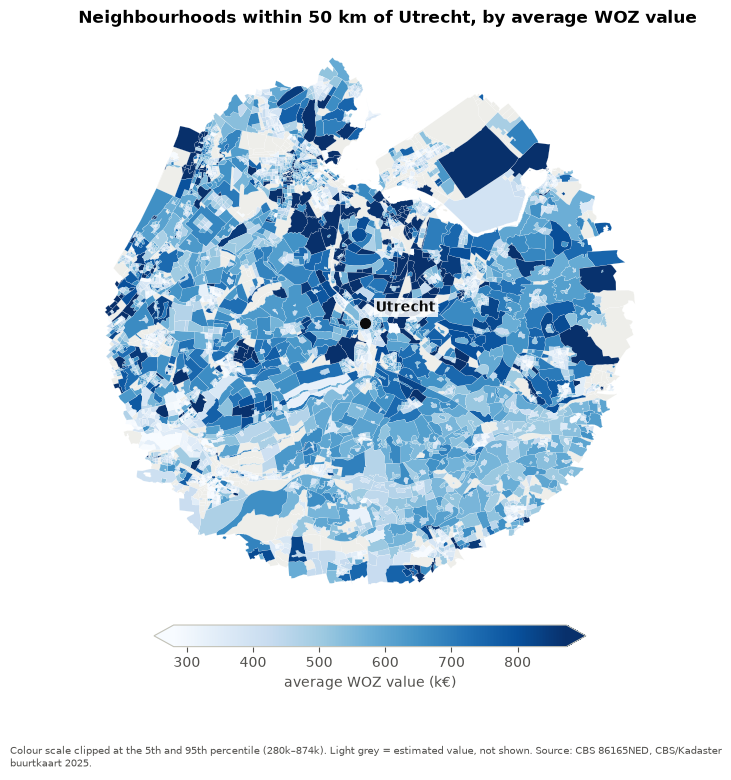

In [2]:
shapes = gpd.read_file(ROOT / "data" / "processed" / "buurten_simplified.geojson")
m = shapes.merge(d[["WijkenEnBuurten", "avg_woz_value_k_eur", "woz_estimated", "dist_to_city_km"]],
                 left_on="buurtcode", right_on="WijkenEnBuurten")
m = m[m["dist_to_city_km"] <= 50].to_crs(28992)

measured = m[~m["woz_estimated"]]
lo, hi = measured["avg_woz_value_k_eur"].quantile([0.05, 0.95])

fig, ax = plt.subplots(figsize=(7.5, 7.5))
m[m["woz_estimated"]].plot(ax=ax, color="#eeeeea", edgecolor="white", linewidth=0.1)
measured.plot(ax=ax, column="avg_woz_value_k_eur", cmap="Blues", vmin=lo, vmax=hi,
              edgecolor="white", linewidth=0.1, legend=True,
              legend_kwds={"label": "average WOZ value (k€)", "orientation": "horizontal",
                           "shrink": 0.6, "pad": 0.02})
city = m[m["dist_to_city_km"] < 1]
cx, cy = d.loc[d["dist_to_city_km"].idxmin(), ["x_rd", "y_rd"]]
ax.plot(cx, cy, marker="o", markersize=7, color=INK)
ax.annotate(ANCHOR, (cx, cy), xytext=(8, 8), textcoords="offset points", color=INK, weight="bold",
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 1.5})
ax.set_axis_off()
ax.set_title(f"Neighbourhoods within 50 km of {ANCHOR}, by average WOZ value", loc="left")
fig.text(0.02, 0.0, f"Colour scale clipped at the 5th and 95th percentile ({lo:.0f}k–{hi:.0f}k). "
        "Light grey = estimated value, not shown. Source: CBS 86165NED, CBS/Kadaster buurtkaart 2025.",
        fontsize=7.5, color=MUTED, va="top", wrap=True)
plt.tight_layout(); fig.savefig(OUT / "01_map.png", dpi=150, bbox_inches="tight"); plt.show()

**Caption (what the newcomer should conclude):** Darker means a higher average home value.
Utrecht itself is not the darkest spot; the darkest neighbourhoods sit just around it, mostly to
the east and north-east. The lighter, lower-value areas are further out, especially to the south.
Big rural neighbourhoods take up most of the map but hold few homes, so the map shows where
value is, not where most people live.

## View 2 · Does moving further out make it cheaper?

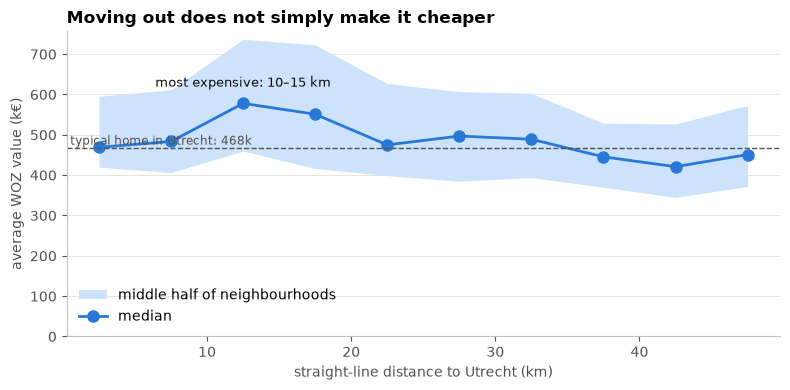

           0.25   0.50   0.75
band                         
[0, 5)    420.0  469.0  596.0
[5, 10)   406.0  484.0  612.0
[10, 15)  460.0  578.0  737.0
[15, 20)  416.0  551.0  723.0
[20, 25)  399.0  475.0  627.0
[25, 30)  385.0  497.0  607.0
[30, 35)  394.0  489.0  603.0
[35, 40)  370.0  446.0  529.0
[40, 45)  345.0  421.0  527.0
[45, 50)  372.0  451.0  573.0


In [3]:
near = d[(d["dist_to_city_km"] <= 50) & ~d["woz_estimated"]].copy()
near["band"] = pd.cut(near["dist_to_city_km"], bins=range(0, 55, 5), right=False)
b = near.groupby("band", observed=True)["avg_woz_value_k_eur"].quantile([0.25, 0.5, 0.75]).unstack()
x = np.array([i.left + 2.5 for i in b.index])

fig, ax = plt.subplots(figsize=(8, 4))
ax.fill_between(x, b[0.25], b[0.75], color=BLUE_LIGHT, linewidth=0, label="middle half of neighbourhoods")
ax.plot(x, b[0.5], color=BLUE, linewidth=2, marker="o", markersize=8, label="median")
ax.axhline(city_woz, color=MUTED, linewidth=1, linestyle="--")
ax.text(x[0] - 2, city_woz, f"typical home in {ANCHOR}: {city_woz:.0f}k", va="bottom", ha="left",
        color=MUTED, fontsize=8.5)
peak = b[0.5].idxmax()
ax.annotate(f"most expensive: {peak.left}–{peak.right} km", (peak.left + 2.5, b[0.5].max()),
            xytext=(0, 12), textcoords="offset points", ha="center", color=INK, fontsize=9)
ax.set_xlabel(f"straight-line distance to {ANCHOR} (km)")
ax.set_ylabel("average WOZ value (k€)")
ax.set_ylim(bottom=0)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.6); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower left")
ax.set_title("Moving out does not simply make it cheaper", loc="left")
plt.tight_layout(); fig.savefig(OUT / "02_distance.png", dpi=150, bbox_inches="tight"); plt.show()
print(b.round(0))

**Caption (what the newcomer should conclude):** Moving out of Utrecht does not make housing
cheaper straight away. The ring at 10-20 km is the most expensive (median 551-578k against 468k
for a typical home in the city). Only beyond about 35 km does the median drop below the city, and
even then the middle half of neighbourhoods spans 150-180k, so distance alone is a poor guide.

## View 3 · Can I actually rent there?

Within the default distance, every neighbourhood as a dot. The shaded corner is what the story is
looking for: lower value than a typical home in the city **and** a real share of private rentals.
Highlighted dots also pass the urban and supermarket conditions.

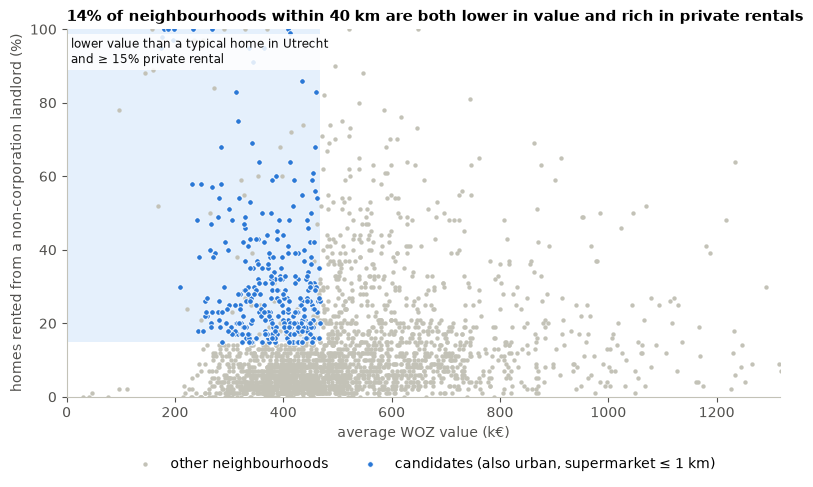

neighbourhoods in zone: 2637
lower value than the city: 1316 (50%)
private rent >= threshold: 899 (34%)
both: 374 | candidates (all conditions): 309


In [4]:
zone = d[(d["dist_to_city_km"] <= settings["max_km"]) & ~d["woz_estimated"] & ~d["rent_estimated"]
         & (d["dwelling_count"] >= settings["min_dwellings"])]
lower = zone["avg_woz_value_k_eur"] < city_woz
renty = zone["pct_rent_private"] >= settings["min_private_rent_pct"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.fill_between([0, city_woz], settings["min_private_rent_pct"], 100, color=BLUE_LIGHT, alpha=0.5, linewidth=0)
other = zone[~zone["candidate"]]
cand = zone[zone["candidate"]]
ax.scatter(other["avg_woz_value_k_eur"], other["pct_rent_private"], s=10, color=GREY, linewidths=0,
           label="other neighbourhoods")
ax.scatter(cand["avg_woz_value_k_eur"], cand["pct_rent_private"], s=16, color=BLUE,
           edgecolors="white", linewidths=0.6, label="candidates (also urban, supermarket ≤ 1 km)")
ax.set_xlim(0, zone["avg_woz_value_k_eur"].quantile(0.99))
ax.set_ylim(0, min(100, zone["pct_rent_private"].quantile(0.995) + 5))
ax.set_xlabel("average WOZ value (k€)")
ax.set_ylabel("homes rented from a non-corporation landlord (%)")
ax.text(8, 98, f"lower value than a typical home in {ANCHOR}\nand ≥ {settings['min_private_rent_pct']}% private rental",
        va="top", ha="left", fontsize=8.5, color=INK,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 2})
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
share = (lower & renty).mean()
ax.set_title(f"{share:.0%} of neighbourhoods within {settings['max_km']} km are both lower in value "
             "and rich in private rentals", loc="left", fontsize=11)
plt.tight_layout(); fig.savefig(OUT / "03_tradeoff.png", dpi=150, bbox_inches="tight"); plt.show()

print("neighbourhoods in zone:", len(zone))
print("lower value than the city:", int(lower.sum()), f"({lower.mean():.0%})")
print("private rent >= threshold:", int(renty.sum()), f"({renty.mean():.0%})")
print("both:", int((lower & renty).sum()), "| candidates (all conditions):", len(cand))

**Caption (what the newcomer should conclude):** Lower value and rentable rarely come together.
Within 40 km, half of the neighbourhoods are below Utrecht's typical home value and a third have
at least 15% private rentals, but only 374 of 2,637 (14%) have both. After also asking for an
urban area with a supermarket within 1 km, 309 remain: those are the blue dots, and the
starting list for the app.

## View 4 · So where do I start looking?

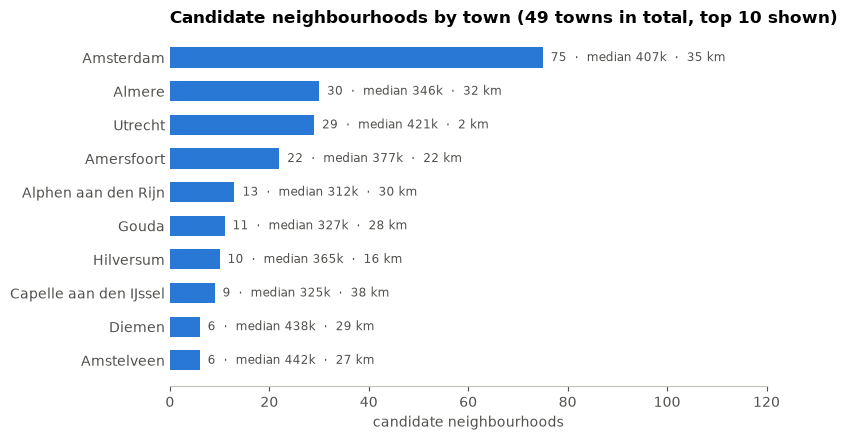

,neighbourhoods,median_woz,median_km
municipality,,,
Amsterdam,75,407.0,34.829532
Almere,30,346.0,31.772372
Utrecht,29,421.0,1.686775
Amersfoort,22,377.0,21.650910
Alphen aan den Rijn,13,312.0,30.146773
Gouda,11,327.0,28.001192
Hilversum,10,365.0,15.510264
Capelle aan den IJssel,9,325.0,38.492640
Diemen,6,438.5,28.802263


In [5]:
by_town = (d[d["candidate"]].groupby("municipality")
           .agg(neighbourhoods=("candidate", "size"),
                median_woz=("avg_woz_value_k_eur", "median"),
                median_km=("dist_to_city_km", "median"))
           .sort_values("neighbourhoods", ascending=False))
top = by_town.head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index, top["neighbourhoods"], color=BLUE, height=0.6)
for y, (n, w, k) in enumerate(top[["neighbourhoods", "median_woz", "median_km"]].itertuples(index=False)):
    ax.text(n, y, f"  {int(n)}  ·  median {w:.0f}k  ·  {k:.0f} km", va="center", fontsize=8.5, color=MUTED)
ax.set_xlabel("candidate neighbourhoods")
ax.set_xlim(0, top["neighbourhoods"].max() * 1.6)
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.set_title(f"Candidate neighbourhoods by town ({len(by_town)} towns in total, top {len(top)} shown)", loc="left")
plt.tight_layout(); fig.savefig(OUT / "04_shortlist.png", dpi=150, bbox_inches="tight"); plt.show()
by_town.head(15)

**Caption (what the newcomer should conclude):** The 309 candidates are spread over 49 towns, but
most sit in a handful of them: Amsterdam (75), Almere (30), Utrecht itself (29) and Amersfoort (22).
So the cheaper option is not only "further out": the cheaper parts of Utrecht and of the bigger
cities nearby are where lower values and private rentals meet. A lower WOZ in a big city can also
just mean smaller flats, which the app should make visible.

## The default view, and why

The app opens on exactly these settings (`DEFAULTS` in `app/helpers.py`).

| setting | value | why |
|---|---|---|
| max distance | 40 km | Close enough for a daily commute, and it still includes Amsterdam, Almere and Amersfoort, which have a direct train to Utrecht. The list grows fast with distance (20 km: 71, 30 km: 166, 40 km: 309, 50 km: 545), so 50 km would mostly add places that are too far to travel every day. |
| min private rental | 15 % | About 1 in 7 homes. That is clearly more than a typical neighbourhood (national median is 9%) but not so strict that only a few areas pass (10%: 419, 20%: 228, 25%: 168). |
| urbanity | class 1-3 | At least 1,000 addresses per km2, so shops and public transport are nearby. Allowing class 4 adds only 10 neighbourhoods (319 vs 309), so the choice barely changes the answer. |
| supermarket | ≤ 1 km by road | Roughly a 12-15 minute walk; a newcomer often has no car. Going stricter (0.5 km) removes 40% of the list, going looser (1.5 km) adds only 25. |
| min homes | 50 | An average over a handful of homes says little. It hardly matters in practice (20: 314, 100: 305), which tells me the result is not driven by tiny neighbourhoods. |
| estimated values | excluded | The shortlist should only rest on measured values. Including the estimates adds just 1 neighbourhood (310 vs 309), so excluding them costs nothing. |

In [6]:
# how sensitive is the shortlist to each default? (change one at a time)
rows = []
for key, values in {"max_km": [20, 30, 40, 50], "min_private_rent_pct": [10, 15, 20, 25],
                    "max_supermarket_km": [0.5, 1.0, 1.5, 2.0]}.items():
    for v in values:
        n = int(candidates(df, ANCHOR, **{key: v})[0]["candidate"].sum())
        rows.append({"setting": key, "value": v, "candidates": n, "default": v == DEFAULTS[key]})
pd.DataFrame(rows)

,setting,value,candidates,default
0,max_km,20.0,71,False
1,max_km,30.0,166,False
2,max_km,40.0,309,True
3,max_km,50.0,545,False
4,min_private_rent_pct,10.0,419,False
5,min_private_rent_pct,15.0,309,True
6,min_private_rent_pct,20.0,228,False
7,min_private_rent_pct,25.0,168,False
8,max_supermarket_km,0.5,188,False
9,max_supermarket_km,1.0,309,True
